# scDiffusion KNN discriminability: a near-constant score

On the saved Tabula Muris subset, the all-gene KNN has AUC **0.5033** while predicting every test cell as generated; RF separates the same test set with AUC **1.0000**. The KNN score is nearly constant, and both query classes select predominantly generated neighbors. It uses the saved Tabula Muris scDiffusion samples following the instructions from scDiffusion README.

The upstream `scDiffusion/exp_script/script_static_eval.ipynb` uses five Euclidean neighbors, uniform votes, and a 70/30 split with `random_state=1`. Its `knn_classify()` reads `.X`, even though the caller computes PCA. We reproduce those classifier settings, inspect votes and distances, and compare classifiers on the same split. Real is label 1; generated is label 0.

The configuration below uses 1,000 cells per source to keep the experiment small.

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import sklearn
import pyrootutils
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, pairwise_distances, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

root = pyrootutils.find_root(search_from=Path.cwd(), indicator=".git")
# Change REAL_PATH and SIM_PATH if your data is located elsewhere
REAL_PATH = root / "data/tabula_muris/all.h5ad"
SIM_PATH = root.parent / "scDiffusion/data/sim_muris_decoded.npy"

OUTPUT_DIR = root / "experiments/outputs/scdiffusion_knn_degeneracy"
N_PER_SOURCE = 1000
SAMPLE_SEED = 42
SPLIT_SEED = 1
N_NEIGHBORS = 5
N_PCS = 50

In [2]:
adata = sc.read_h5ad(REAL_PATH)
adata.var_names_make_unique()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

rng = np.random.default_rng(SAMPLE_SEED)
real_indices = rng.choice(adata.n_obs, 2 * N_PER_SOURCE, replace=False)
real = adata.X[real_indices[:N_PER_SOURCE]].toarray().astype(np.float32)
real_control = adata.X[real_indices[N_PER_SOURCE:]].toarray().astype(np.float32)
saved_sim = np.load(SIM_PATH, mmap_mode="r")
sim_indices = rng.choice(len(saved_sim), N_PER_SOURCE, replace=False)
sim = np.array(saved_sim[sim_indices])
# np.savez(OUTPUT_DIR / "selected_indices.npz", real=real_indices, generated=sim_indices)
print(f"Each source: {real.shape[0]} cells × {real.shape[1]} genes")
del adata, saved_sim

Each source: 1000 cells × 18996 genes


## Joint UMAP of real and generated cells

Performing UMAP on combined dataset (2000 samples, 18996 features) across 2 datasets...


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP completed. Generating visualizations...


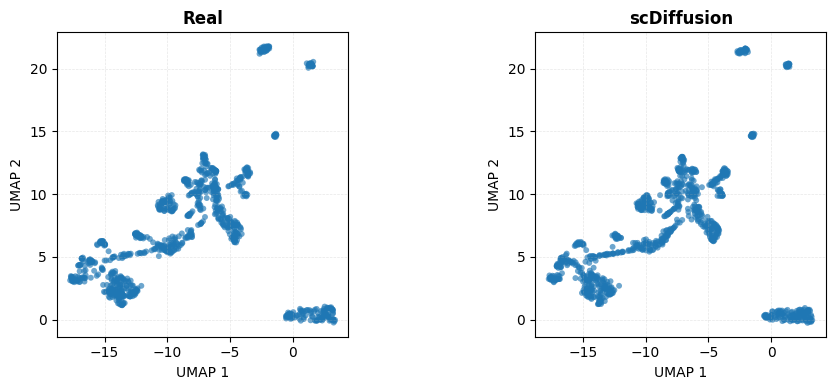

In [3]:
from scdeepsim.plot import compare_umap

umap_embeddings, fig = compare_umap(
    [real, sim],
    title_list=["Real", "scDiffusion"],
    n_neighbors=15, min_dist=0.3, random_state=SAMPLE_SEED,
    figsize=(10, 4), alpha=0.65, s=18,
    share_axes=True, equal_aspect=True,
)
plt.show()

## Reproduce the classifier and inspect its scores

AUC is computed from `predict_proba`, not hard labels. All predictions belonging to one class does not by itself imply AUC 0.5: the scores could still rank the two sources. The score-frequency table checks whether that ranking information has also disappeared.

In [4]:
X = np.vstack([real, sim])
y = np.r_[np.ones(N_PER_SOURCE, dtype=int), np.zeros(N_PER_SOURCE, dtype=int)]
train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.3, random_state=SPLIT_SEED
)
y_train, y_test = y[train_idx], y[test_idx]
X_train, X_test = X[train_idx], X[test_idx]
knn = KNeighborsClassifier(n_neighbors=N_NEIGHBORS, n_jobs=4).fit(X_train, y_train)
p_real = knn.predict_proba(X_test)[:, 1]
predicted = knn.predict(X_test)
print("Training counts [generated, real]:", np.bincount(y_train))
print("Test counts [generated, real]:", np.bincount(y_test))
print(f"AUC: {roc_auc_score(y_test, p_real):.6f}")
print(f"Accuracy: {accuracy_score(y_test, predicted):.6f}")
display(pd.DataFrame(confusion_matrix(y_test, predicted, labels=[0, 1]),
                     index=["true generated", "true real"],
                     columns=["predicted generated", "predicted real"]))
score_counts = pd.crosstab(
    pd.Series(p_real, name="P(real)"),
    pd.Series(np.where(y_test == 1, "real", "generated"), name="query source")
)
display(score_counts)

Training counts [generated, real]: [699 701]
Test counts [generated, real]: [301 299]
AUC: 0.503344
Accuracy: 0.501667


,predicted generated,predicted real
true generated,301,0
true real,299,0


query source,generated,real
P(real),,
0.0,301,297
0.2,0,2


## Which class supplies the neighbors?

Compute distances from test cells to training cells only. A ratio below one means a query is closer to a generated training cell than to any real training cell. Nearest-neighbor votes expose whether both query classes are being attracted to the generated sample cloud.

In [5]:
distances = pairwise_distances(X_test, X_train, metric="euclidean", n_jobs=1)
neighbor_idx = np.argsort(distances, axis=1)[:, :N_NEIGHBORS]
neighbor_real_fraction = y_train[neighbor_idx].mean(axis=1)
np.testing.assert_allclose(neighbor_real_fraction, p_real)
nearest_real = distances[:, y_train == 1].min(axis=1)
nearest_generated = distances[:, y_train == 0].min(axis=1)
queries = pd.DataFrame({
    "query_source": np.where(y_test == 1, "real", "generated"),
    "p_real": p_real,
    "all_neighbors_generated": neighbor_real_fraction == 0,
    "nearest_real": nearest_real,
    "nearest_generated": nearest_generated,
    "distance_ratio_gen_over_real": nearest_generated / nearest_real,
})
display(queries.groupby("query_source").agg(
    n=("p_real", "size"),
    mean_p_real=("p_real", "mean"),
    fraction_all_neighbors_generated=("all_neighbors_generated", "mean"),
    median_nearest_real=("nearest_real", "median"),
    median_nearest_generated=("nearest_generated", "median"),
    median_distance_ratio=("distance_ratio_gen_over_real", "median"),
))
del distances

,n,mean_p_real,fraction_all_neighbors_generated,median_nearest_real,median_nearest_generated,median_distance_ratio
query_source,,,,,,
generated,301,0.000000,1.000000,32.106853,7.954134,0.257187
real,299,0.001338,0.993311,50.546841,40.412319,0.787996


## Variance of real and generated cells

Use all 1,000 real and all 1,000 generated cells, including both training and test cells, in normalized log1p expression space. Compute variance separately for each source. The sum of per-gene variances measures total variation around each source's own mean. When the mean profiles are close, lower generated variance can favor generated cells as Euclidean neighbors for both query sources, consistent with the neighbor assignments above.

In [6]:
total_variance = pd.Series({
    "real": real.var(axis=0, dtype=np.float64).sum(),
    "generated": sim.var(axis=0, dtype=np.float64).sum(),
}, name="sum_gene_variances")
mean_gap_sq = np.sum((real.mean(axis=0, dtype=np.float64) - sim.mean(axis=0, dtype=np.float64)) ** 2)
display(total_variance.to_frame())
print(f"Generated / real variance: {total_variance['generated'] / total_variance['real']:.3f}")
print(f"Squared distance between mean profiles: {mean_gap_sq:.2f}")

,sum_gene_variances
real,2269.207597
generated,723.832967


Generated / real variance: 0.319
Squared distance between mean profiles: 5.51


## Same-split comparisons and a real-versus-real control

Keep the cells and train/test indices fixed. The RF uses 100 trees with unrestricted depth. The control replaces generated samples with a disjoint random sample of real cells and assigns those cells label 0. It checks what chance-level discrimination looks like when the sources actually come from the same dataset.

In [7]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=SAMPLE_SEED,
    n_jobs=4,
)
rf.fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]

X_control = np.vstack([real, real_control])
knn_control = KNeighborsClassifier(n_neighbors=N_NEIGHBORS, n_jobs=4)
knn_control.fit(X_control[train_idx], y_train)
p_control = knn_control.predict_proba(X_control[test_idx])[:, 1]

scores = {
    "KNN, all genes": p_real,
    "RF, all genes": p_rf,
    "KNN, real vs real": p_control,
}

comparison = pd.DataFrame([
    {
        "method": name,
        "auc": roc_auc_score(y_test, probabilities),
        "accuracy": accuracy_score(y_test, probabilities > 0.5),
        "fraction_predicted_label_0": np.mean(probabilities <= 0.5),
        "fraction_score_exactly_0": np.mean(probabilities == 0),
        "n_distinct_scores": len(np.unique(probabilities)),
    }
    for name, probabilities in scores.items()
]).set_index("method")

display(comparison)

,auc,accuracy,fraction_predicted_label_0,fraction_score_exactly_0,n_distinct_scores
method,,,,,
"KNN, all genes",0.503344,0.501667,1.000000,0.996667,2
"RF, all genes",1.000000,1.000000,0.501667,0.323333,22
"KNN, real vs real",0.505022,0.503333,0.665000,0.066667,6


## Minimal mechanism: equal means, different variances

Generate $R\sim N(0,I_d)$ and $G\sim N(0,s^2I_d)$ with $d=1000$. At $s=0.35$, expected squared distances per dimension are 2 (real–real), 1.1225 (real–generated), and 0.245 (generated–generated). In high dimensions these distances concentrate, so both kinds of query can select generated neighbors. Yet the radius distinguishes the distributions easily.

The $s=1$ control uses the same random draws and split. The only intervention is scaling the generated cloud. Radius is an illustrative discriminator with an analytically known center, not a proposed metric for the biological data.

In [8]:
toy_rng = np.random.default_rng(7)
toy_real = toy_rng.normal(size=(500, 1000)).astype(np.float32)
toy_generated_base = toy_rng.normal(size=toy_real.shape).astype(np.float32)
toy_y = np.r_[np.ones(500, dtype=int), np.zeros(500, dtype=int)]
toy_train, toy_test = train_test_split(np.arange(1000), test_size=0.3, random_state=1)
toy_rows = []
for scale in [1.0, 0.35]:
    toy_X = np.vstack([toy_real, scale * toy_generated_base])
    model = KNeighborsClassifier(n_neighbors=5, n_jobs=4).fit(toy_X[toy_train], toy_y[toy_train])
    probability = model.predict_proba(toy_X[toy_test])[:, 1]
    toy_rows.append({
        "generated_scale": scale,
        "knn_auc": roc_auc_score(toy_y[toy_test], probability),
        "fraction_score_exactly_0": np.mean(probability == 0),
        "fraction_predicted_generated": np.mean(probability < 0.5),
        "radius_auc": roc_auc_score(toy_y[toy_test], np.linalg.norm(toy_X[toy_test], axis=1)),
    })
toy_results = pd.DataFrame(toy_rows).set_index("generated_scale")
display(toy_results)

,knn_auc,fraction_score_exactly_0,fraction_predicted_generated,radius_auc
generated_scale,,,,
1.00,0.542491,0.023333,0.433333,0.456598
0.35,0.500000,1.000000,1.000000,1.000000
